In [ ]:
!pip install Sastrawi

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 209.7/209.7 kB 3.4 MB/s eta 0:00:00


In [ ]:
import pandas as pd
import re
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud

In [ ]:
#: Pemilihan dan Eksplorasi Dataset
from google.colab import files
uploaded = files.upload()

Saving Shopee_Sampled_Reviews.csv to Shopee_Sampled_Reviews.csv


In [ ]:
# 1. Load dataset
df = pd.read_csv('Shopee_Sampled_Reviews.csv')

In [ ]:
# 2. Pembersihan data
# Fungsi untuk membersihkan teks
def clean_text(text):
    if pd.isna(text):
        return ""
    # Ubah ke huruf kecil
    text = text.lower()
    # Hapus tanda baca, angka, dan karakter khusus
    text = re.sub(r'[^\w\s]', '', text)
    # Hapus spasi berlebih
    text = re.sub(r'\s+', ' ', text).strip()
    return text

# Terapkan pembersihan teks
df['content_clean'] = df['content'].apply(clean_text)

In [ ]:
# 3. Preprocessing tambahan
# Inisialisasi stemmer dan stopword remover untuk bahasa Indonesia
factory = StemmerFactory()
stemmer = factory.create_stemmer()
stopword_factory = StopWordRemoverFactory()
stopwords = stopword_factory.get_stop_words()

# Fungsi untuk stemming dan menghapus stopwords
def preprocess_text(text):
    # Stemming
    text = stemmer.stem(text)
    # Hapus stopwords
    text = ' '.join(word for word in text.split() if word not in stopwords)
    return text

# Terapkan preprocessing
df['content_processed'] = df['content_clean'].apply(preprocess_text)

In [ ]:
# 4. Pelabelan sentimen berdasarkan skor
def label_sentiment(score):
    if score <= 2:
        return 'negatif'
    elif score == 3:
        return 'netral'
    else:
        return 'positif'

df['sentiment'] = df['score'].apply(label_sentiment)

In [ ]:
# 5. Ekstraksi fitur
vectorizer = TfidfVectorizer(max_features=1000)
X = vectorizer.fit_transform(df['content_processed'].fillna(''))
y = df['sentiment']

In [ ]:
# 6. Split data menjadi data latih dan uji
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
# 7. Latih model Naive Bayes
model = MultinomialNB()
model.fit(X_train, y_train)

MultinomialNB()

In [ ]:
# 8. Evaluasi model
y_pred = model.predict(X_test)
print("Hasil Evaluasi Model:")
print(classification_report(y_test, y_pred))

Hasil Evaluasi Model:
              precision    recall  f1-score   support

     negatif       0.51      0.91      0.66       188
      netral       0.00      0.00      0.00       108
     positif       0.77      0.62      0.69       204

    accuracy                           0.60       500
   macro avg       0.43      0.51      0.45       500
weighted avg       0.51      0.60      0.53       500



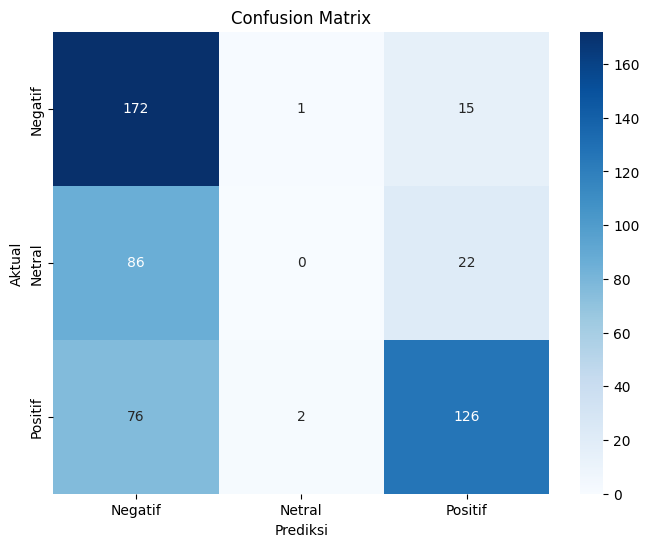

In [ ]:
# Visualisasi confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=['negatif', 'netral', 'positif'])
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Negatif', 'Netral', 'Positif'], yticklabels=['Negatif', 'Netral', 'Positif'])
plt.title('Confusion Matrix')
plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.show()

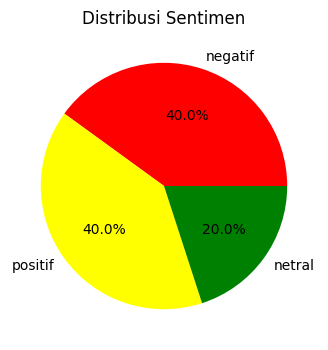

In [ ]:
# 9. Visualisasi distribusi sentimen
plt.figure(figsize=(6, 4))
df['sentiment'].value_counts().plot(kind='pie', autopct='%1.1f%%', colors=['red', 'yellow', 'green'])
plt.title('Distribusi Sentimen')
plt.ylabel('')
plt.show()

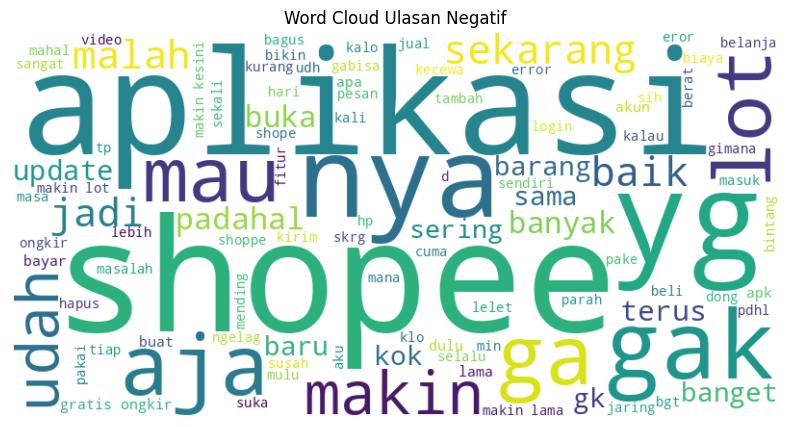

In [ ]:
# 10. Word cloud untuk ulasan negatif
negatif_text = ' '.join(df[df['sentiment'] == 'negatif']['content_processed'])
wordcloud = WordCloud(width=800, height=400, background_color='white', max_words=100).generate(negatif_text)
plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Word Cloud Ulasan Negatif')
plt.show()

In [ ]:
# 11. Prediksi untuk ulasan baru
new_reviews = ["aplikasi lemot banget", "shopee mantap banyak promo"]
new_reviews_clean = [preprocess_text(clean_text(review)) for review in new_reviews]
new_reviews_tfidf = vectorizer.transform(new_reviews_clean)
predictions = model.predict(new_reviews_tfidf)

for review, pred in zip(new_reviews, predictions):
    print(f"Ulasan: {review}\nSentimen: {pred}\n")

Ulasan: aplikasi lemot banget
Sentimen: negatif

Ulasan: shopee mantap banyak promo
Sentimen: positif

